In [2]:
import pandas as pd

In [3]:
pd.DataFrame({"Yes":[10, 30], "No":[20, 40]})

,Yes,No
0,10,20
1,30,40


In [4]:
pd.DataFrame({'Bob': ['I liked it.', 'It was awful.'], 'Sue': ['Pretty good.', 'Bland.']})

,Bob,Sue
0,I liked it.,Pretty good.
1,It was awful.,Bland.


In [5]:
pd.DataFrame({'Bob': ['I liked it.', 'It was awful.'], 
              'Sue': ['Pretty good.', 'Bland.']},
             index=['Product A', 'Product B'])

,Bob,Sue
Product A,I liked it.,Pretty good.
Product B,It was awful.,Bland.


In [6]:
pd.DataFrame({
    'Sugar': [100, 300],
    'Milk': [10, 50],
    'Evil Eye': [4, 9]
}, 
index=["Cake", "Osu Milk"])

,Sugar,Milk,Evil Eye
Cake,100,10,4
Osu Milk,300,50,9


In [7]:
pd.Series([1, 2, 3, 4, 5])

0    1
1    2
2    3
3    4
4    5
dtype: int64

In [8]:
pd.Series([30, 35, 40], index=['2015 Sales', '2016 Sales', '2017 Sales'], name='Product A')

2015 Sales    30
2016 Sales    35
2017 Sales    40
Name: Product A, dtype: int64

[-300, -300, -300, -297, -296, -296, -296, -296, -294, -293, -293, -292, -292, -291, -291, -291, -290, -289, -289, -288, -288, -287, -287, -286, -285, -285, -285, -284, -284, -284, -283, -283, -283, -282, -281, -281, -281, -280, -280, -278, -276, -275, -275, -274, -274, -273, -273, -273, -272, -272, -272, -270, -269, -269, -269, -267, -267, -266, -266, -265, -265, -264, -264, -263, -263, -262, -260, -259, -258, -256, -255, -254, -253, -253, -252, -251, -251, -250, -249, -248, -247, -246, -243, -242, -241, -241, -240, -239, -239, -239, -238, -238, -238, -236, -236, -236, -234, -234, -232, -232, -232, -231, -230, -230, -228, -228, -226, -226, -226, -225, -225, -225, -225, -225, -223, -221, -220, -220, -219, -218, -218, -217, -217, -217, -216, -216, -216, -216, -214, -213, -213, -211, -211, -210, -210, -209, -208, -208, -208, -207, -206, -206, -204, -202, -201, -201, -201, -201, -201, -201, -201, -201, -200, -200, -200, -199, -199, -197, -196, -191, -190, -190, -190, -189, -189, -189, -18

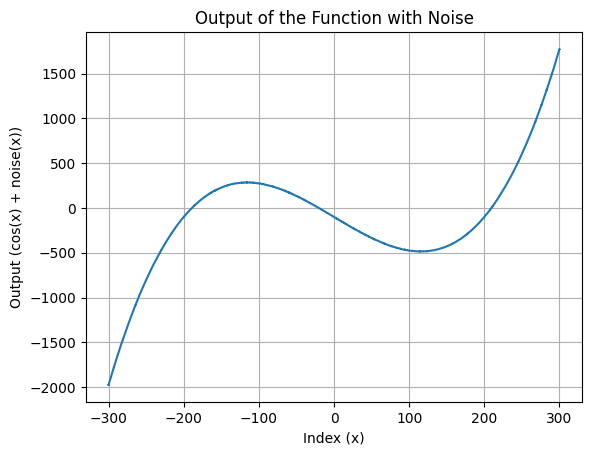

In [189]:
import random
import math

# Generate 100 random indexes from -100 to 100
size = 1000
noise_range = 0.01*100

random_indexes = sorted([random.randint(-300, 300) for _ in range(size)])

print(random_indexes)




def func_noise(x):
    # Calculate cosine of x
    funx = (x/20)**3 - 5*x - 100
    
    # Generate random noise
    noise = random.uniform(-noise_range, noise_range)  # Adjust range as needed
    
    # Add noise to cosine value
    result = funx + noise
    
    return result

random_list = [func_noise(x) for x in random_indexes]

print(random_list)

import matplotlib.pyplot as plt

# Plot the data
plt.plot(random_indexes, random_list)
plt.xlabel('Index (x)')
plt.ylabel('Output (cos(x) + noise(x))')
plt.title('Output of the Function with Noise')
plt.grid(True)
plt.show()


In [184]:
def find_closest_index(x, index_list):
    closest_index = None
    min_difference = float('inf')
    
    for i, value in enumerate(index_list):
        difference = abs(x - value)
        if difference < min_difference:
            min_difference = difference
            closest_index = i
    
    # If x is to the left of the closest value, adjust index
    if x < index_list[closest_index]:
        closest_index -= 1
        if closest_index < 0:
            closest_index = 0
    
    return closest_index


def newton_descent(indexes, list, initial_guess, step = 1, tolerance=1e-2, max_iterations=100):
    x = initial_guess
    iteration = 0
    
    while True:
        index = find_closest_index(x, indexes)
        index_h = find_closest_index(x+step, indexes)
        y = list[index]
        dy = list[index_h] - list[index] - 1
        
        if abs(y) < tolerance or iteration >= max_iterations:
            break
        
        x = x - y / dy
        
        if iteration % 10 == 0:
            print(f"Iteration: {iteration} (X Value: {x}, Y Value: {y}, dY Step: {dy})")
        iteration += 1
    
    return x

newton_descent(random_indexes, random_list, -300, 10, 5e-1, 101)

Iteration: 0 (X Value: -292.11147346124176, Y Value: -1946.3675282568915, dY Step: 246.73397733960974)
Iteration: 10 (X Value: -237.86064333574421, Y Value: -678.6072765308317, dY Step: 161.43274170711481)
Iteration: 20 (X Value: -208.16951433328893, Y Value: -242.95207306011227, dY Step: 131.86824883335353)
Iteration: 30 (X Value: -195.2129947638546, Y Value: -70.66434016596163, dY Step: 79.0883540314671)
Iteration: 40 (X Value: -190.7130032244086, Y Value: -24.740932548422425, dY Step: 80.16267480376695)
Iteration: 50 (X Value: -188.9515267581236, Y Value: 1.0864022257062649, dY Step: 75.9971701864317)
Iteration: 60 (X Value: -188.85639969756195, Y Value: 1.0864022257062649, dY Step: 75.9971701864317)
Iteration: 70 (X Value: -188.99935268160615, Y Value: 1.0864022257062649, dY Step: 75.9971701864317)
Iteration: 80 (X Value: -188.9042256210445, Y Value: 1.0864022257062649, dY Step: 75.9971701864317)
Iteration: 90 (X Value: -188.80909856048285, Y Value: 1.0864022257062649, dY Step: 75.

-188.95205154452705

In [206]:
import math

def normal_pdf(x, mu, sigma):
    # Calculate the probability density function of the normal distribution at x
    return 1 / (math.sqrt(2 * math.pi) * sigma) * math.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

def trapezoidal_rule(func, a, b, n):
    # Trapezoidal rule for numerical integration
    h = (b - a) / n
    result = 0.5 * (func(a) + func(b))
    for i in range(1, n):
        result += func(a + i * h)
    result *= h
    return result

# Define parameters of the normal distribution
mu = 0  # Mean
sigma = 1  # Standard deviation

# Define segment bounds
a = -10000
b = 10000

# Calculate area under the segment using the trapezoidal rule
area = trapezoidal_rule(lambda x: normal_pdf(x, mu, sigma), a, b, n=1000)
print("Area under the segment of the normal curve:", area)


Area under the segment of the normal curve: 7.978845608028654
